# Probabilistic Anomaly Detection on Chest X-rays: a Rigorous Evaluation (v3)
**What changed from v1**
1. **Patient-level splits** (a patient never appears in both train and test). Full mode uses the official NIH split.
2. **Baselines**: mean-image, PCA, age/sex/view-only (confound check), pretrained DenseNet features + Mahalanobis / kNN, and a supervised linear probe (a reference ceiling).
3. **Multiple seeds** for stochastic models and **patient-clustered bootstrap 95% CIs**, with paired differences against PCA.
4. **Confound check**: results stratified by view position (PA vs AP).
5. **Calibration** of the Bayesian Network (Brier score, ECE, reliability plot) instead of only AUROC.
6. Thresholds come from the **validation split**, never the test set.

**Practicals covered:** 1 (joint/marginal/conditional), 2 (Bayesian Network), 3 (MRF), 4 (RBM), 5 (Markov chain, illustrative), 6 (Autoencoder).

**Honest scope notes**
- `DATA_MODE="sample"` (5,606 images) works out of the box. `DATA_MODE="full"` (112k images, ~45 GB download) is written but was not tested by the author, so expect to debug paths.
- NIH has no pixel masks here, so the MRF can only be judged by image-level score and by eye, not by Dice/IoU.
- NIH labels are NLP-mined and noisy. Do not describe results as clinical performance.

**v3 additions (Section 11 onwards, run after Section 9)**
7. Native-resolution (224 px) multi-layer DenseNet features, L2-normalised kNN, with k and layer set chosen on the validation split.
8. Optional PatchCore-style patch-level kNN (local anomaly scores).
9. Evidence fusion: unsupervised ECDF averaging, logistic fusion, and a multi-node Bayesian Network, against isotonic/logistic **calibration baselines**.
10. Paired patient-clustered bootstrap tests against the age/sex/view confound model and against the v2 kNN.

**Honest note:** nothing here guarantees AUROC 0.80. Choosing k, layers and fusion weights uses validation labels, so describe those steps as *light supervision for hyperparameter selection* in the paper. For the biggest expected gain set `DATA_MODE = "full"` (more normal reference images) and re-run from the top.


## 0. Setup and configuration

In [1]:
!pip install -q pgmpy scikit-learn opencv-python-headless kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 13.8 MB/s eta 0:00:00


In [2]:
import os, time, hashlib, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import LedoitWolf
warnings.filterwarnings("ignore")

# ------------------------- CONFIG -------------------------
DATA_MODE  = "sample"   # "sample" = 5,606 images (works out of the box) | "full" = 112k images, official split
IMG        = 128        # must be divisible by 16
N_SEEDS    = 5          # use 3 in full mode to save time
AE_EPOCHS  = 40
RBM_EPOCHS = 60
BETA       = 1.0        # MRF smoothness weight
N_BOOT     = 300
if DATA_MODE == "full":
    MAX_TRAIN_ALL, MAX_VAL, MAX_TEST = 30000, 4000, 8000
else:
    MAX_TRAIN_ALL = MAX_VAL = MAX_TEST = None
# -----------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| mode:", DATA_MODE, "| img:", IMG)

Device: cuda | mode: sample | img: 128


## 1. Helper functions (pure NumPy / sklearn)

In [3]:
def icm_mrf(R, t, scale, beta=1.0, iters=8):
    # Binary MRF on a 4-connected grid, solved with ICM (checkerboard updates).
    # E(y) = sum_i unary(y_i, R_i) + beta * sum_(i,j) [y_i != y_j]
    s = ((R - t) / scale).astype(np.float32)          # >0 => evidence of anomaly
    y = (s > 0).astype(np.float32)
    ii, jj = np.indices(R.shape[1:])
    masks = [((ii + jj) % 2 == k)[None] for k in (0, 1)]
    def nbr(y):
        p = np.pad(y, ((0, 0), (1, 1), (1, 1)))
        return p[:, :-2, 1:-1] + p[:, 2:, 1:-1] + p[:, 1:-1, :-2] + p[:, 1:-1, 2:]
    for _ in range(iters):
        for m in masks:
            n1 = nbr(y)
            E1 = -s + beta * (4 - n1)     # energy if label = 1
            E0 =  s + beta * n1           # energy if label = 0
            y = np.where(m, (E1 < E0).astype(np.float32), y)
    return y.astype(np.uint8)

def mrf_masks(R, t, scale, beta=1.0, iters=8, chunk=500):
    out = np.empty(R.shape, dtype=np.uint8)
    for i in range(0, len(R), chunk):
        out[i:i+chunk] = icm_mrf(R[i:i+chunk], t, scale, beta, iters)
    return out

def bootstrap_auc(y, groups, scores, n_boot=300, ref=None, seed=0):
    # Patient-clustered bootstrap: resample PATIENTS, not images.
    y = np.asarray(y); groups = np.asarray(groups)
    rng = np.random.default_rng(seed)
    ug, inv = np.unique(groups, return_inverse=True)
    idx_by_g = [np.where(inv == k)[0] for k in range(len(ug))]
    boots = {k: [] for k in scores}
    for _ in range(n_boot):
        pick = rng.integers(0, len(ug), len(ug))
        idx = np.concatenate([idx_by_g[p] for p in pick])
        yb = y[idx]
        if yb.min() == yb.max():
            continue
        for k, s in scores.items():
            boots[k].append(roc_auc_score(yb, s[idx]))
    rows = []
    for k, s in scores.items():
        b = np.array(boots[k])
        row = {"Method": k, "AUROC": roc_auc_score(y, s),
               "CI_low": np.percentile(b, 2.5), "CI_high": np.percentile(b, 97.5)}
        if ref is not None and k != ref:
            d = b - np.array(boots[ref])
            row.update({"dAUROC_vs_ref": roc_auc_score(y, s) - roc_auc_score(y, scores[ref]),
                        "d_low": np.percentile(d, 2.5), "d_high": np.percentile(d, 97.5)})
        rows.append(row)
    return pd.DataFrame(rows)

def brier_ece(p, y, bins=10):
    p = np.asarray(p, float); y = np.asarray(y, float)
    edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for i in range(bins):
        hi = (p < edges[i+1]) if i < bins - 1 else (p <= edges[i+1])
        m = (p >= edges[i]) & hi
        if m.any():
            ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(np.mean((p - y) ** 2)), float(ece)

def orient(s_val, y_val, s_te):
    # Pick the sign of a score using the VALIDATION split only.
    if roc_auc_score(y_val, s_val) >= 0.5:
        return s_val, s_te, +1
    return -s_val, -s_te, -1

## 2. Data: NIH ChestX-ray14 with patient-level splits
Normal = "No Finding". Anomaly = any finding. Pathology families (an image can belong to several): alveolar (Pneumonia/Infiltration/Consolidation), effusion (Effusion/Atelectasis), nodule/mass (Nodule/Mass).

In [4]:
import kagglehub
slug = "nih-chest-xrays/sample" if DATA_MODE == "sample" else "nih-chest-xrays/data"
root = kagglehub.dataset_download(slug)
csvs, pngs, txts = {}, {}, {}
for r, _, fs in os.walk(root):
    for f in fs:
        p = os.path.join(r, f); fl = f.lower()
        if fl.endswith(".png"): pngs[f] = p
        elif fl.endswith(".csv"): csvs[f] = p
        elif fl.endswith(".txt"): txts[f] = p
print("Found", len(pngs), "png files under", root)

csv_name = "sample_labels.csv" if DATA_MODE == "sample" else "Data_Entry_2017.csv"
meta = pd.read_csv(csvs[csv_name])
meta.columns = [c.strip() for c in meta.columns]
meta = meta.rename(columns={"Image Index": "file", "Finding Labels": "finding", "Patient ID": "patient",
                            "Patient Age": "age", "Patient Gender": "sex", "View Position": "view"})
meta = meta[["file", "finding", "patient", "age", "sex", "view"]]
meta = meta[meta.file.isin(pngs)].reset_index(drop=True)
meta["age"] = pd.to_numeric(meta.age.astype(str).str.extract(r"(\d+)")[0], errors="coerce")
meta.loc[meta.age > 100, "age"] = np.nan
meta["age"] = meta.age.fillna(meta.age.median())
meta["is_normal"] = meta.finding.str.strip() == "No Finding"
meta["fam_alv"] = meta.finding.str.contains("Pneumonia|Infiltration|Consolidation")
meta["fam_eff"] = meta.finding.str.contains("Effusion|Atelectasis")
meta["fam_nod"] = meta.finding.str.contains("Nodule|Mass")

rs = np.random.default_rng(0)
if DATA_MODE == "sample":
    pats = rs.permutation(meta.patient.unique()); n = len(pats)
    tr_p, va_p = set(pats[:int(.60*n)]), set(pats[int(.60*n):int(.75*n)])
    meta["split"] = np.where(meta.patient.isin(tr_p), "train", np.where(meta.patient.isin(va_p), "val", "test"))
else:
    tv = set(open(txts["train_val_list.txt"]).read().split())
    tl = set(open(txts["test_list.txt"]).read().split())
    meta = meta[meta.file.isin(tv | tl)].reset_index(drop=True)
    tvp = rs.permutation(meta[meta.file.isin(tv)].patient.unique()); k = int(.85 * len(tvp))
    tr_p, va_p = set(tvp[:k]), set(tvp[k:])
    meta["split"] = np.where(meta.file.isin(tl), "test", np.where(meta.patient.isin(tr_p), "train", "val"))

P = {s: set(meta[meta.split == s].patient) for s in ["train", "val", "test"]}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "patient leakage!"
print("Patient-level split verified: no patient appears in two splits.")

def take(df, n):
    return df.copy() if (n is None or len(df) <= n) else df.sample(n=n, random_state=0)
tr_all = take(meta[meta.split == "train"], MAX_TRAIN_ALL).reset_index(drop=True)
val    = take(meta[meta.split == "val"],   MAX_VAL).reset_index(drop=True)
te     = take(meta[meta.split == "test"],  MAX_TEST).reset_index(drop=True)
m_norm = tr_all.is_normal.values            # unsupervised models train on these only
summary = pd.DataFrame({s: {"images": len(d), "patients": d.patient.nunique(),
                            "normal": int(d.is_normal.sum()), "abnormal": int((~d.is_normal).sum())}
                        for s, d in [("train(all)", tr_all), ("val", val), ("test", te)]}).T
print(summary)
print("Unsupervised training set (normal images in train patients):", int(m_norm.sum()))

Using Colab cache for faster access to the 'sample' dataset.
Found 5606 png files under /kaggle/input/sample
Patient-level split verified: no patient appears in two splits.
            images  patients  normal  abnormal
train(all)    3349      2538    1807      1542
val            855       634     468       387
test          1402      1058     769       633
Unsupervised training set (normal images in train patients): 1807


In [5]:
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
import cv2
os.makedirs("./cache", exist_ok=True)

def load_one(path):
    im = Image.open(path).convert("L").resize((IMG, IMG), Image.BILINEAR)
    a = np.array(im, dtype=np.uint8)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(a)   # exposure normalisation

def load_split(df, name):
    key = hashlib.md5("|".join(df.file).encode()).hexdigest()[:10]
    cp = f"./cache/{DATA_MODE}_{IMG}_{name}_{key}.npy"
    if os.path.exists(cp):
        arr = np.load(cp)
    else:
        t0 = time.time()
        with ThreadPoolExecutor(8) as ex:
            arr = np.stack(list(ex.map(load_one, [pngs[f] for f in df.file])))
        np.save(cp, arr); print(f"  loaded {name}: {arr.shape} in {time.time()-t0:.0f}s")
    return torch.from_numpy(arr).float().div(127.5).sub(1).unsqueeze(1)    # [-1, 1]

X_tr_all = load_split(tr_all, "train")
X_val    = load_split(val, "val")
X_te     = load_split(te, "test")
X_tr_norm = X_tr_all[torch.from_numpy(m_norm)]
print("X_tr_norm", tuple(X_tr_norm.shape), "| X_val", tuple(X_val.shape), "| X_te", tuple(X_te.shape))

  loaded train: (3349, 128, 128) in 46s
  loaded val: (855, 128, 128) in 10s
  loaded test: (1402, 128, 128) in 16s
X_tr_norm (1807, 1, 128, 128) | X_val (855, 1, 128, 128) | X_te (1402, 1, 128, 128)


## 3. Baselines (no deep generative model needed)

In [6]:
y_val = (~val.is_normal.values).astype(int)
y_te  = (~te.is_normal.values).astype(int)
val_norm = val.is_normal.values
det_val, det_te = {}, {}          # deterministic methods (no seed dependence)

def to64(X):
    X = F.adaptive_avg_pool2d(X, 64) if X.shape[-1] != 64 else X
    return X.reshape(len(X), -1).numpy()
A_trn, A_val, A_te = to64(X_tr_norm), to64(X_val), to64(X_te)

# (a) Mean-image distance
mu = A_trn.mean(0)
det_val["Mean-image distance"] = ((A_val - mu) ** 2).mean(1)
det_te["Mean-image distance"]  = ((A_te - mu) ** 2).mean(1)

# (b) PCA reconstruction error (64 components, trained on normals only)
pca = PCA(n_components=64, svd_solver="randomized", random_state=0).fit(A_trn)
def pca_err(A): return ((A - pca.inverse_transform(pca.transform(A))) ** 2).mean(1)
det_val["PCA recon error"] = pca_err(A_val); det_te["PCA recon error"] = pca_err(A_te)

# (c) Confound baseline: age + sex + view only (supervised, trained on train patients)
def demo(d): return np.c_[d.age.values / 100.0, (d.sex.values == "M").astype(float), (d.view.values == "PA").astype(float)]
lr_demo = LogisticRegression(max_iter=1000).fit(demo(tr_all), (~tr_all.is_normal.values).astype(int))
det_val["Age/sex/view only (supervised)"] = lr_demo.predict_proba(demo(val))[:, 1]
det_te["Age/sex/view only (supervised)"]  = lr_demo.predict_proba(demo(te))[:, 1]

for k in det_te:
    print(f"{k:35s} val AUROC {roc_auc_score(y_val, det_val[k]):.3f} | test AUROC {roc_auc_score(y_te, det_te[k]):.3f}")

Mean-image distance                 val AUROC 0.515 | test AUROC 0.503
PCA recon error                     val AUROC 0.516 | test AUROC 0.527
Age/sex/view only (supervised)      val AUROC 0.578 | test AUROC 0.591


## 4. Pretrained-feature density models (the upgrade over a from-scratch autoencoder)
DenseNet-121 (ImageNet weights) features are fitted with a Gaussian (Mahalanobis, Ledoit-Wolf shrinkage) and a kNN density on **normal** training images only. A **linear probe** trained with labels is included as a supervised reference.

In [7]:
import torchvision
try:
    dn = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1)
except Exception:
    dn = torchvision.models.densenet121(pretrained=True)
dn.classifier = nn.Identity(); dn = dn.to(device).eval()
imn_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
imn_std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def extract(X, bs=128):
    out = []
    for i in range(0, len(X), bs):
        xb = (X[i:i+bs].to(device) + 1) / 2
        xb = F.interpolate(xb, size=224, mode="bilinear", align_corners=False).repeat(1, 3, 1, 1)
        out.append(dn((xb - imn_mean) / imn_std).float().cpu())
    return torch.cat(out).numpy()

t0 = time.time()
f_tr_all, f_val, f_te = extract(X_tr_all), extract(X_val), extract(X_te)
f_trn = f_tr_all[m_norm]
print("features:", f_trn.shape, f"({time.time()-t0:.0f}s)")

# Mahalanobis (Gaussian density on normal features)
lw = LedoitWolf().fit(f_trn)
det_val["DenseNet + Mahalanobis"] = lw.mahalanobis(f_val)
det_te["DenseNet + Mahalanobis"]  = lw.mahalanobis(f_te)

# kNN distance (k=5)
@torch.no_grad()
def knn_score(Fq, Fref, k=5, chunk=1000):
    ref = torch.from_numpy(Fref).to(device); out = []
    for i in range(0, len(Fq), chunk):
        d = torch.cdist(torch.from_numpy(Fq[i:i+chunk]).to(device), ref)
        out.append(d.topk(k, largest=False).values.mean(1).cpu())
    return torch.cat(out).numpy()
det_val["DenseNet + kNN(5)"] = knn_score(f_val, f_trn)
det_te["DenseNet + kNN(5)"]  = knn_score(f_te, f_trn)

# Supervised linear probe (reference ceiling, uses labels); C chosen on validation
sc = StandardScaler().fit(f_tr_all)
best = None
for C in [0.01, 0.1, 1.0]:
    clf = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(f_tr_all), (~tr_all.is_normal.values).astype(int))
    a = roc_auc_score(y_val, clf.predict_proba(sc.transform(f_val))[:, 1])
    if best is None or a > best[0]: best = (a, C, clf)
clf = best[2]; print(f"Linear probe: best C={best[1]} (val AUROC {best[0]:.3f})")
det_val["DenseNet linear probe (supervised)"] = clf.predict_proba(sc.transform(f_val))[:, 1]
det_te["DenseNet linear probe (supervised)"]  = clf.predict_proba(sc.transform(f_te))[:, 1]

for k in ["DenseNet + Mahalanobis", "DenseNet + kNN(5)", "DenseNet linear probe (supervised)"]:
    print(f"{k:38s} val AUROC {roc_auc_score(y_val, det_val[k]):.3f} | test AUROC {roc_auc_score(y_te, det_te[k]):.3f}")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 159MB/s]


features: (1807, 1024) (19s)
Linear probe: best C=0.01 (val AUROC 0.698)
DenseNet + Mahalanobis                 val AUROC 0.661 | test AUROC 0.630
DenseNet + kNN(5)                      val AUROC 0.652 | test AUROC 0.655
DenseNet linear probe (supervised)     val AUROC 0.698 | test AUROC 0.691


## 5. Your PGM pipeline: Autoencoder (P6) -> RBM prior (P4) -> MRF (P3), repeated over seeds

In [8]:
class ConvAE(nn.Module):
    def __init__(self, latent=128, img=IMG):
        super().__init__()
        s = img // 16
        def blk(i, o):  return nn.Sequential(nn.Conv2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.LeakyReLU(0.2))
        def dblk(i, o): return nn.Sequential(nn.ConvTranspose2d(i, o, 4, 2, 1), nn.BatchNorm2d(o), nn.LeakyReLU(0.2))
        self.s = s
        self.enc = nn.Sequential(blk(1, 32), blk(32, 64), blk(64, 128), blk(128, 256),
                                 nn.Flatten(), nn.Linear(256 * s * s, latent))
        self.fc = nn.Linear(latent, 256 * s * s)
        self.dec = nn.Sequential(nn.BatchNorm2d(256), nn.LeakyReLU(0.2),
                                 dblk(256, 128), dblk(128, 64), dblk(64, 32),
                                 nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Tanh())
    def forward(self, x):
        z = self.enc(x)
        return self.dec(self.fc(z).view(-1, 256, self.s, self.s)), z

def train_ae(X, seed, epochs):
    torch.manual_seed(seed); np.random.seed(seed)
    ae = ConvAE().to(device); opt = optim.Adam(ae.parameters(), 1e-3)
    g = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(X, batch_size=64, shuffle=True, generator=g)
    losses = []
    for ep in range(epochs):
        ae.train(); tot = 0
        for xb in loader:
            xb = xb.to(device); rec, _ = ae(xb)
            loss = F.mse_loss(rec, xb); opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item()
        losses.append(tot / len(loader))
    return ae, losses

@torch.no_grad()
def run_ae(ae, X, want_rec=True, bs=256):
    ae.eval(); recs, zs = [], []
    for i in range(0, len(X), bs):
        r, z = ae(X[i:i+bs].to(device)); zs.append(z.cpu())
        if want_rec: recs.append(r.cpu())
    return (torch.cat(recs) if want_rec else None), torch.cat(zs)

class RBM:
    def __init__(self, nv, nh, dev):
        self.W = torch.randn(nv, nh, device=dev) * 0.01
        self.b = torch.zeros(nv, device=dev); self.c = torch.zeros(nh, device=dev)
    def ph(self, v): return torch.sigmoid(v @ self.W + self.c)
    def pv(self, h): return torch.sigmoid(h @ self.W.t() + self.b)
    def cd1(self, v0, lr):
        ph0 = self.ph(v0); h0 = torch.bernoulli(ph0); pv1 = self.pv(h0); ph1 = self.ph(pv1); n = v0.shape[0]
        self.W += lr * (v0.t() @ ph0 - pv1.t() @ ph1) / n
        self.b += lr * (v0 - pv1).mean(0); self.c += lr * (ph0 - ph1).mean(0)
    def free_energy(self, v): return -(v @ self.b) - F.softplus(v @ self.W + self.c).sum(1)

def residual_scores(R, t, scale):
    Rf = R.reshape(len(R), -1); k = max(1, int(0.01 * Rf.shape[1]))
    top = np.partition(Rf, -k, axis=1)[:, -k:].mean(1)
    masks = mrf_masks(R, t, scale, BETA)
    return Rf.mean(1), top, masks.reshape(len(R), -1).mean(1), masks

STOCH = ["ConvAE mean residual", "ConvAE top-1% residual", "ConvAE + MRF area", "RBM free energy (oriented)"]
S_val = {k: [] for k in STOCH}; S_te = {k: [] for k in STOCH}
vis = {}; vis_idx = np.where(y_te == 1)[0][:5]
baseline_mse = ((X_tr_norm - X_tr_norm.mean(0, keepdim=True)) ** 2).mean().item()
print(f"Mean-image baseline MSE = {baseline_mse:.4f}")

for seed in range(N_SEEDS):
    t0 = time.time()
    ae, losses = train_ae(X_tr_norm, seed, AE_EPOCHS)
    if losses[-1] > 0.8 * baseline_mse: print(f"  WARNING seed {seed}: AE barely beats mean image")
    _, z_trn = run_ae(ae, X_tr_norm, want_rec=False)
    rec_val, z_val = run_ae(ae, X_val); rec_te, z_te = run_ae(ae, X_te)

    sub = X_tr_norm[:500]; rec_sub, _ = run_ae(ae, sub)                   # threshold stats from TRAIN normals
    R_sub = ((sub - rec_sub) ** 2).squeeze(1).numpy()
    t_thr, scale = np.percentile(R_sub, 95), R_sub.std()
    R_val = ((X_val - rec_val) ** 2).squeeze(1).numpy(); R_te = ((X_te - rec_te) ** 2).squeeze(1).numpy()
    a_val, top_val, mrf_val, _      = residual_scores(R_val, t_thr, scale)
    a_te,  top_te,  mrf_te,  M_te_  = residual_scores(R_te,  t_thr, scale)

    z_mu, z_sd = z_trn.mean(0), z_trn.std(0) + 1e-6
    to01 = lambda z: torch.sigmoid((z - z_mu) / z_sd)
    rbm = RBM(z_trn.shape[1], 256, device); Ztr = to01(z_trn).to(device)
    for ep in range(RBM_EPOCHS):
        perm = torch.randperm(len(Ztr), device=device)
        for i in range(0, len(Ztr), 128): rbm.cd1(Ztr[perm[i:i+128]], 0.05)
    e_val = rbm.free_energy(to01(z_val).to(device)).cpu().numpy()
    e_te  = rbm.free_energy(to01(z_te).to(device)).cpu().numpy()
    e_val, e_te, sign = orient(e_val, y_val, e_te)                       # direction chosen on validation only

    for name, sv, st in [("ConvAE mean residual", a_val, a_te), ("ConvAE top-1% residual", top_val, top_te),
                         ("ConvAE + MRF area", mrf_val, mrf_te), ("RBM free energy (oriented)", e_val, e_te)]:
        S_val[name].append(sv); S_te[name].append(st)
    if seed == 0:
        vis = {"x": X_te[vis_idx, 0].numpy(), "rec": rec_te[vis_idx, 0].numpy(), "R": R_te[vis_idx], "M": M_te_[vis_idx],
               "loss": losses}
    print(f"seed {seed}: AE loss {losses[-1]:.4f} | test AUROC  mean {roc_auc_score(y_te, a_te):.3f}  "
          f"top1% {roc_auc_score(y_te, top_te):.3f}  MRF {roc_auc_score(y_te, mrf_te):.3f}  "
          f"RBM {roc_auc_score(y_te, e_te):.3f} (sign {sign:+d}) | {time.time()-t0:.0f}s")
    del rec_val, rec_te, R_val, R_te, M_te_

Mean-image baseline MSE = 0.1780
seed 0: AE loss 0.0183 | test AUROC  mean 0.537  top1% 0.549  MRF 0.545  RBM 0.548 (sign +1) | 69s
seed 1: AE loss 0.0193 | test AUROC  mean 0.543  top1% 0.551  MRF 0.552  RBM 0.523 (sign +1) | 72s
seed 2: AE loss 0.0189 | test AUROC  mean 0.539  top1% 0.549  MRF 0.544  RBM 0.551 (sign +1) | 73s
seed 3: AE loss 0.0189 | test AUROC  mean 0.538  top1% 0.556  MRF 0.543  RBM 0.531 (sign +1) | 74s
seed 4: AE loss 0.0181 | test AUROC  mean 0.542  top1% 0.555  MRF 0.548  RBM 0.535 (sign +1) | 73s


## 6. Evaluation (patient-clustered bootstrap CIs, seed statistics, family and view breakdowns)

In [9]:
scores_te = dict(det_te)
for k in STOCH: scores_te[k] = S_te[k][0]            # seed 0 for CIs; seed spread reported separately
REF = "PCA recon error"
tab = bootstrap_auc(y_te, te.patient.values, scores_te, n_boot=N_BOOT, ref=REF)
seed_std = {k: (np.mean([roc_auc_score(y_te, s) for s in S_te[k]]), np.std([roc_auc_score(y_te, s) for s in S_te[k]])) for k in STOCH}
tab["Seed mean +/- std"] = tab.Method.map(lambda k: f"{seed_std[k][0]:.3f} +/- {seed_std[k][1]:.3f}" if k in seed_std else "-")
tab = tab.sort_values("AUROC", ascending=False).reset_index(drop=True)
print("=== Any finding vs normal (test split, patient-clustered 95% CI; d_* = difference vs PCA baseline) ===")
display(tab.round(3))
tab.to_csv("results_pooled.csv", index=False)

fams = {"Any finding": None, "Alveolar opacity": "fam_alv", "Effusion/Atelectasis": "fam_eff", "Nodule/Mass": "fam_nod"}
fam_tab, ns = {}, {}
for fname, col in fams.items():
    m = np.ones(len(te), bool) if col is None else (te.is_normal.values | te[col].values)
    yy = (~te.is_normal.values[m]).astype(int); ns[fname] = (int(yy.sum()), int((1 - yy).sum()))
    fam_tab[fname] = {k: roc_auc_score(yy, s[m]) for k, s in scores_te.items()}
print("\n=== AUROC by pathology family (positives, negatives):", ns)
fam_df = pd.DataFrame(fam_tab).round(3); display(fam_df); fam_df.to_csv("results_families.csv")

view_tab = {}
for v in ["PA", "AP"]:
    m = te.view.values == v
    if m.sum() > 0 and len(set(y_te[m])) == 2:
        view_tab[f"{v} only (n={int(m.sum())})"] = {k: roc_auc_score(y_te[m], s[m]) for k, s in scores_te.items()}
print("\n=== Confound check: AUROC within a single view position ===")
display(pd.DataFrame(view_tab).round(3))

above = tab[tab.CI_low > 0.5].Method.tolist(); below = tab[tab.CI_high < 0.5].Method.tolist()
print("\nSignificantly ABOVE chance (CI lower bound > 0.5):", above)
print("Significantly BELOW chance (anti-informative):     ", below)

=== Any finding vs normal (test split, patient-clustered 95% CI; d_* = difference vs PCA baseline) ===


,Method,AUROC,CI_low,CI_high,dAUROC_vs_ref,d_low,d_high,Seed mean +/- std
0,DenseNet linear probe (supervised),0.691,0.665,0.718,0.164,0.126,0.205,-
1,DenseNet + kNN(5),0.655,0.625,0.683,0.128,0.092,0.166,-
2,DenseNet + Mahalanobis,0.630,0.600,0.660,0.103,0.067,0.139,-
3,Age/sex/view only (supervised),0.591,0.557,0.623,0.063,0.019,0.114,-
4,ConvAE top-1% residual,0.549,0.517,0.580,0.022,0.001,0.048,0.552 +/- 0.003
5,RBM free energy (oriented),0.548,0.517,0.577,0.021,-0.014,0.066,0.538 +/- 0.011
6,ConvAE + MRF area,0.545,0.517,0.574,0.017,0.006,0.030,0.546 +/- 0.003
7,ConvAE mean residual,0.537,0.509,0.565,0.010,-0.001,0.021,0.540 +/- 0.002
8,PCA recon error,0.527,0.500,0.557,NaN,NaN,NaN,-
9,Mean-image distance,0.503,0.473,0.530,-0.024,-0.054,0.006,-



=== AUROC by pathology family (positives, negatives): {'Any finding': (633, 769), 'Alveolar opacity': (292, 769), 'Effusion/Atelectasis': (256, 769), 'Nodule/Mass': (133, 769)}


,Any finding,Alveolar opacity,Effusion/Atelectasis,Nodule/Mass
Mean-image distance,0.503,0.499,0.484,0.493
PCA recon error,0.527,0.536,0.484,0.556
Age/sex/view only (supervised),0.591,0.606,0.613,0.563
DenseNet + Mahalanobis,0.630,0.666,0.638,0.608
DenseNet + kNN(5),0.655,0.688,0.685,0.616
DenseNet linear probe (supervised),0.691,0.698,0.731,0.683
ConvAE mean residual,0.537,0.561,0.489,0.575
ConvAE top-1% residual,0.549,0.574,0.540,0.560
ConvAE + MRF area,0.545,0.564,0.493,0.584
RBM free energy (oriented),0.548,0.566,0.556,0.559



=== Confound check: AUROC within a single view position ===


,PA only (n=850),AP only (n=552)
Mean-image distance,0.512,0.481
PCA recon error,0.525,0.534
Age/sex/view only (supervised),0.562,0.531
DenseNet + Mahalanobis,0.627,0.575
DenseNet + kNN(5),0.649,0.613
DenseNet linear probe (supervised),0.685,0.672
ConvAE mean residual,0.527,0.540
ConvAE top-1% residual,0.511,0.525
ConvAE + MRF area,0.543,0.544
RBM free energy (oriented),0.504,0.593



Significantly ABOVE chance (CI lower bound > 0.5): ['DenseNet linear probe (supervised)', 'DenseNet + kNN(5)', 'DenseNet + Mahalanobis', 'Age/sex/view only (supervised)', 'ConvAE top-1% residual', 'RBM free energy (oriented)', 'ConvAE + MRF area', 'ConvAE mean residual']
Significantly BELOW chance (anti-informative):      []


## 7. Bayesian Network with calibration (Practicals 1 and 2)
Flags use thresholds from **validation normals** (95th percentile). CPDs are estimated on the validation split and evaluated on the test split.

Flag rates on val normals (should be ~0.05): {'AnomalyScore': 0.051, 'RBMEnergy': 0.051, 'FeatureDist': 0.051}
Flag rates on val abnormals:                 {'AnomalyScore': 0.052, 'RBMEnergy': 0.044, 'FeatureDist': 0.093}

Practical 1 - Joint P(Disease, AnomalyScore):
AnomalyScore      0      1
Disease                   
0             0.519  0.028
1             0.429  0.023
Sum = 1.0
Marginal P(Disease): {0: 0.547, 1: 0.453}
Conditional P(Disease | AnomalyScore):
AnomalyScore      0      1
Disease                   
0             0.547  0.545
1             0.453  0.455

Bayesian Network on TEST: AUROC 0.552 | Brier 0.2442 | ECE 0.0165
Prevalence-only baseline : AUROC 0.500 | Brier 0.2476 | ECE 0.0011   (BN must beat this Brier to add value)


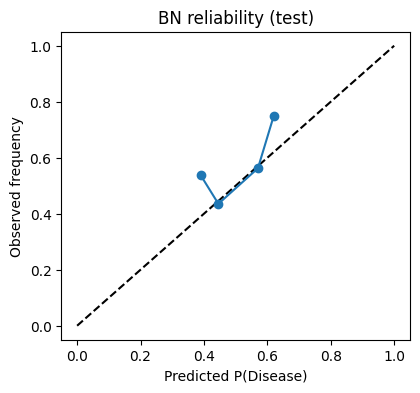

In [10]:
from itertools import product
try:
    from pgmpy.models import DiscreteBayesianNetwork as BN
except ImportError:
    from pgmpy.models import BayesianNetwork as BN
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

def flag(sv, st, q=95):
    thr = np.percentile(sv[val_norm], q); return (sv > thr).astype(int), (st > thr).astype(int)
a_v, a_t = flag(S_val["ConvAE + MRF area"][0], S_te["ConvAE + MRF area"][0])
r_v, r_t = flag(S_val["RBM free energy (oriented)"][0], S_te["RBM free energy (oriented)"][0])
f_v, f_t = flag(det_val["DenseNet + Mahalanobis"], det_te["DenseNet + Mahalanobis"])
g_v, g_t = (val.age.values >= 50).astype(int), (te.age.values >= 50).astype(int)

df = pd.DataFrame({"Age": g_v, "Disease": y_val, "AnomalyScore": a_v, "RBMEnergy": r_v, "FeatureDist": f_v})
print("Flag rates on val normals (should be ~0.05):", df[df.Disease == 0][["AnomalyScore", "RBMEnergy", "FeatureDist"]].mean().round(3).to_dict())
print("Flag rates on val abnormals:                ", df[df.Disease == 1][["AnomalyScore", "RBMEnergy", "FeatureDist"]].mean().round(3).to_dict())

joint = pd.crosstab(df.Disease, df.AnomalyScore, normalize=True)
print("\nPractical 1 - Joint P(Disease, AnomalyScore):"); print(joint.round(3)); print("Sum =", round(float(joint.values.sum()), 6))
print("Marginal P(Disease):", joint.sum(1).round(3).to_dict())
print("Conditional P(Disease | AnomalyScore):"); print(joint.div(joint.sum(0), axis=1).round(3))

bn = BN([("Age", "Disease"), ("Disease", "AnomalyScore"), ("Disease", "RBMEnergy"), ("Disease", "FeatureDist")])
est = BayesianEstimator(bn, df, state_names={c: [0, 1] for c in df.columns})
for node in bn.nodes():
    bn.add_cpds(est.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10))
assert bn.check_model()
infer = VariableElimination(bn)
post = {}
for g, a, r, f in product([0, 1], repeat=4):
    q = infer.query(["Disease"], evidence={"Age": g, "AnomalyScore": a, "RBMEnergy": r, "FeatureDist": f}, show_progress=False)
    post[(g, a, r, f)] = float(q.values[1])
p_te = np.array([post[(g, a, r, f)] for g, a, r, f in zip(g_t, a_t, r_t, f_t)])

prev = float(y_val.mean())
b_bn, e_bn = brier_ece(p_te, y_te); b_pr, e_pr = brier_ece(np.full(len(y_te), prev), y_te)
print(f"\nBayesian Network on TEST: AUROC {roc_auc_score(y_te, p_te):.3f} | Brier {b_bn:.4f} | ECE {e_bn:.4f}")
print(f"Prevalence-only baseline : AUROC 0.500 | Brier {b_pr:.4f} | ECE {e_pr:.4f}   (BN must beat this Brier to add value)")

bins = np.linspace(0, 1, 11); xs, ys = [], []
for i in range(10):
    m = (p_te >= bins[i]) & ((p_te < bins[i+1]) if i < 9 else (p_te <= bins[i+1]))
    if m.sum() >= 10: xs.append(p_te[m].mean()); ys.append(y_te[m].mean())
plt.figure(figsize=(4.5, 4)); plt.plot([0, 1], [0, 1], "k--"); plt.plot(xs, ys, "o-")
plt.xlabel("Predicted P(Disease)"); plt.ylabel("Observed frequency"); plt.title("BN reliability (test)"); plt.show()

## 8. Markov chain (Practical 5): illustrative only
The transition matrix is **assumed**, not estimated from patient data. Do not present it as a finding.

In [11]:
states = ["Stable", "Observation", "Critical"]
Pm = np.array([[0.80, 0.15, 0.05], [0.30, 0.50, 0.20], [0.10, 0.30, 0.60]])
w, v = np.linalg.eig(Pm.T); pi = np.real(v[:, np.argmin(abs(w - 1))]); pi /= pi.sum()
rg = np.random.default_rng(0); s_, cnt = 0, np.zeros(3)
for _ in range(100000):
    s_ = rg.choice(3, p=Pm[s_]); cnt[s_] += 1
print(pd.DataFrame({"analytic": pi, "simulated": cnt / cnt.sum()}, index=states).round(3))

             analytic  simulated
Stable          0.519      0.522
Observation     0.278      0.275
Critical        0.204      0.203


## 9. Figures

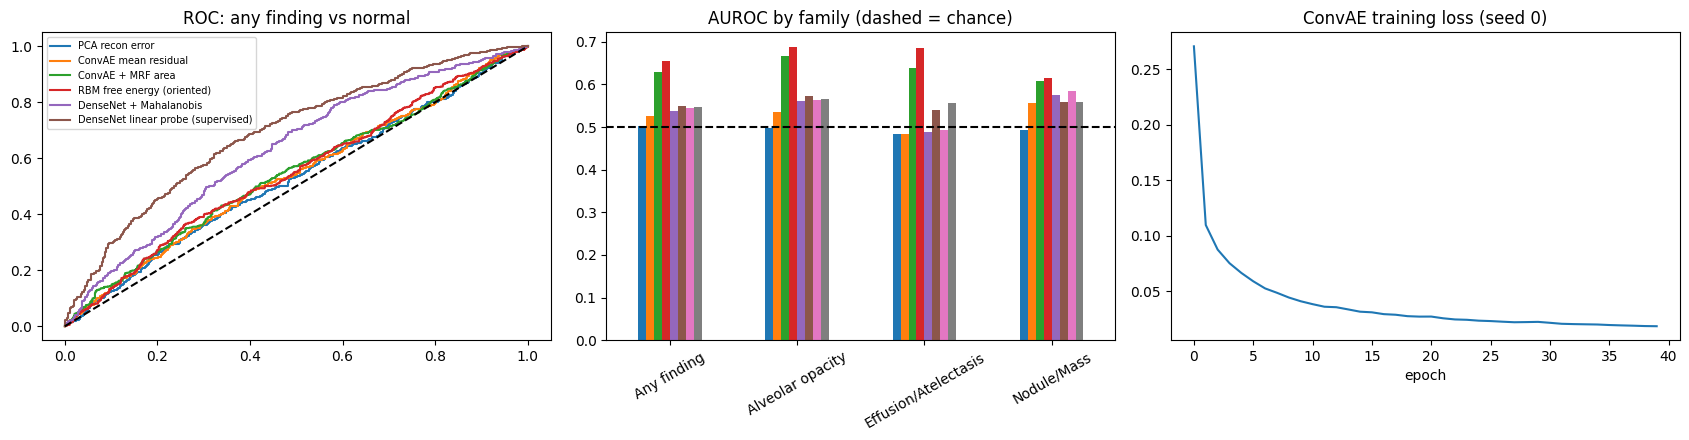

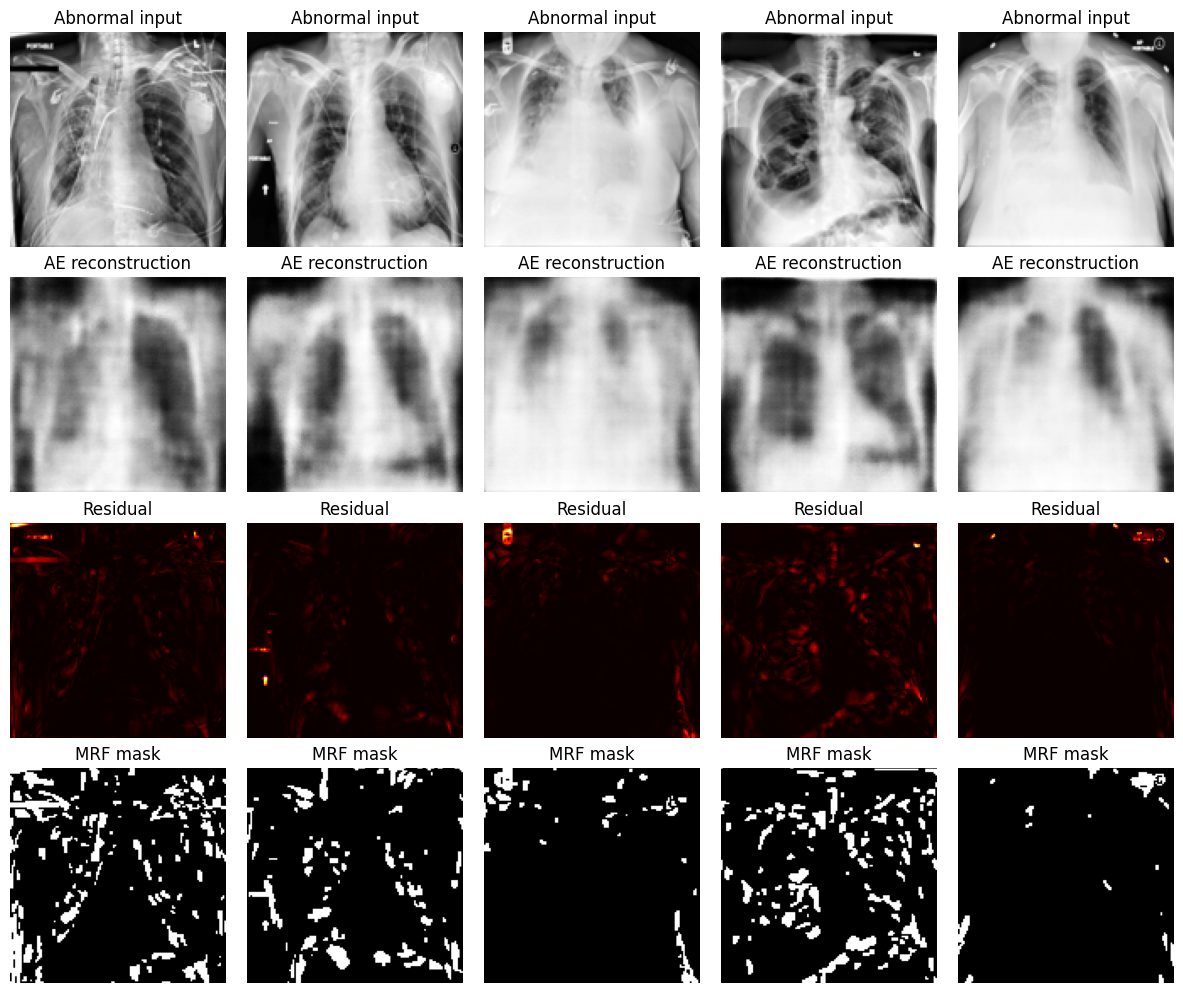

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for k in ["PCA recon error", "ConvAE mean residual", "ConvAE + MRF area", "RBM free energy (oriented)",
          "DenseNet + Mahalanobis", "DenseNet linear probe (supervised)"]:
    f_, t_, _ = roc_curve(y_te, scores_te[k]); ax[0].plot(f_, t_, label=k)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC: any finding vs normal"); ax[0].legend(fontsize=7)
fam_df.drop(index=[i for i in fam_df.index if "supervised" in i]).T.plot.bar(ax=ax[1], legend=False)
ax[1].axhline(0.5, color="k", ls="--"); ax[1].set_title("AUROC by family (dashed = chance)"); ax[1].tick_params(axis="x", rotation=30)
ax[2].plot(vis["loss"]); ax[2].set_title("ConvAE training loss (seed 0)"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for k in range(len(vis["x"])):
    axes[0, k].imshow(vis["x"][k], cmap="gray");    axes[0, k].set_title("Abnormal input")
    axes[1, k].imshow(vis["rec"][k], cmap="gray");  axes[1, k].set_title("AE reconstruction")
    axes[2, k].imshow(vis["R"][k], cmap="hot");     axes[2, k].set_title("Residual")
    axes[3, k].imshow(vis["M"][k], cmap="gray");    axes[3, k].set_title("MRF mask")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

In [13]:
# Paired, patient-clustered bootstrap: is method A better than method B?
def paired_diff(y, groups, s_a, s_b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    codes, uniq = pd.factorize(groups)
    idx_by = [np.where(codes == i)[0] for i in range(len(uniq))]
    d = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        ii = np.concatenate([idx_by[p] for p in pick]); yy = y[ii]
        if yy.min() == yy.max(): continue
        d.append(roc_auc_score(yy, s_a[ii]) - roc_auc_score(yy, s_b[ii]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return roc_auc_score(y, s_a) - roc_auc_score(y, s_b), lo, hi

CONF = "Age/sex/view only (supervised)"
methods = ["DenseNet + kNN(5)", "DenseNet + Mahalanobis", "ConvAE + MRF area",
           "ConvAE top-1% residual", "RBM free energy (oriented)", "PCA recon error"]
subsets = {"All test": np.ones(len(te), bool),
           "PA only": te.view.values == "PA",
           "AP only": te.view.values == "AP"}
rows = []
for sname, m in subsets.items():
    for k in methods:
        d, lo, hi = paired_diff(y_te[m], te.patient.values[m], scores_te[k][m], scores_te[CONF][m])
        rows.append({"Subset": sname, "Method": k, "AUROC diff vs confound": d,
                     "CI_low": lo, "CI_high": hi, "Significant": (lo > 0) or (hi < 0)})
paired_df = pd.DataFrame(rows).round(3)
display(paired_df)
paired_df.to_csv("results_paired_vs_confound.csv", index=False)

# kNN vs Mahalanobis (do they differ at all?)
print("kNN - Mahalanobis:", [round(float(x), 3) for x in
      paired_diff(y_te, te.patient.values, scores_te["DenseNet + kNN(5)"], scores_te["DenseNet + Mahalanobis"])])

,Subset,Method,AUROC diff vs confound,CI_low,CI_high,Significant
0,All test,DenseNet + kNN(5),0.064,0.026,0.103,True
1,All test,DenseNet + Mahalanobis,0.039,0.002,0.077,True
2,All test,ConvAE + MRF area,-0.046,-0.094,0.002,False
3,All test,ConvAE top-1% residual,-0.042,-0.081,-0.003,True
4,All test,RBM free energy (oriented),-0.043,-0.084,-0.001,True
5,All test,PCA recon error,-0.063,-0.112,-0.014,True
6,PA only,DenseNet + kNN(5),0.087,0.031,0.145,True
7,PA only,DenseNet + Mahalanobis,0.065,0.007,0.122,True
8,PA only,ConvAE + MRF area,-0.019,-0.082,0.043,False
9,PA only,ConvAE top-1% residual,-0.051,-0.112,0.010,False


kNN - Mahalanobis: [0.025, 0.011, 0.038]


In [14]:
# BN with a 4-level DenseNet kNN evidence node instead of a binary 5% flag.
# Bin edges come from validation NORMALS only (no test leakage).
edges = np.percentile(det_val["DenseNet + kNN(5)"][val_norm], [50, 80, 95])
def binify(s): return np.digitize(s, edges)          # states 0..3
b_v, b_t = binify(det_val["DenseNet + kNN(5)"]), binify(det_te["DenseNet + kNN(5)"])

df2 = pd.DataFrame({"Age": g_v, "Disease": y_val, "FeatureBin": b_v})
bn2 = BN([("Age", "Disease"), ("Disease", "FeatureBin")])
est2 = BayesianEstimator(bn2, df2, state_names={"Age": [0, 1], "Disease": [0, 1], "FeatureBin": [0, 1, 2, 3]})
for node in bn2.nodes():
    bn2.add_cpds(est2.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10))
assert bn2.check_model()
inf2 = VariableElimination(bn2)
post2 = {(g, b): float(inf2.query(["Disease"], evidence={"Age": g, "FeatureBin": b}, show_progress=False).values[1])
         for g in [0, 1] for b in range(4)}
post_age = {g: float(inf2.query(["Disease"], evidence={"Age": g}, show_progress=False).values[1]) for g in [0, 1]}
p2 = np.array([post2[(g, b)] for g, b in zip(g_t, b_t)])
p_age = np.array([post_age[g] for g in g_t])
p_prev = np.full(len(y_te), float(y_val.mean()))

for name, p in [("BN (Age + DenseNet bins)", p2), ("BN (Age only)", p_age), ("Prevalence only", p_prev)]:
    b, e = brier_ece(p, y_te)
    print(f"{name:26s} AUROC {roc_auc_score(y_te, p):.3f} | Brier {b:.4f} | ECE {e:.4f}")

# Patient-clustered CI for the Brier improvement over prevalence (negative = BN better)
rng = np.random.default_rng(0)
codes, uniq = pd.factorize(te.patient.values)
idx_by = [np.where(codes == i)[0] for i in range(len(uniq))]
bd = []
for _ in range(2000):
    ii = np.concatenate([idx_by[p] for p in rng.integers(0, len(uniq), len(uniq))])
    bd.append(np.mean((p2[ii] - y_te[ii]) ** 2) - np.mean((p_prev[ii] - y_te[ii]) ** 2))
lo, hi = np.percentile(bd, [2.5, 97.5])
print(f"Brier(BN) - Brier(prevalence): {np.mean((p2-y_te)**2)-np.mean((p_prev-y_te)**2):+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")
print("BN beats prevalence significantly" if hi < 0 else "BN does NOT significantly beat prevalence")

BN (Age + DenseNet bins)   AUROC 0.650 | Brier 0.2310 | ECE 0.0179
BN (Age only)              AUROC 0.535 | Brier 0.2466 | ECE 0.0040
Prevalence only            AUROC 0.500 | Brier 0.2476 | ECE 0.0011
Brier(BN) - Brier(prevalence): -0.0167  95% CI [-0.0228, -0.0103]
BN beats prevalence significantly


## 10. How to report this honestly
- Report the pooled table with **CIs** and the **paired difference vs PCA**. Only claim an advantage when the difference CI excludes 0.
- Put the **supervised linear probe** in the table as the reference. Unsupervised methods are expected to be well below it.
- If the age/sex/view-only baseline is above 0.5, say so: part of any score may be confounding, not pathology. Use the view-stratified table.
- Describe the MRF qualitatively unless you add a dataset with pixel/box annotations (e.g. NIH `BBox_List_2017.csv`, RSNA Pneumonia) and report Dice/IoU.
- The Bayesian Network is evaluated on **calibration** (Brier, ECE) versus a prevalence-only baseline.
- State limitations: noisy NLP-mined labels, 128 px resolution, one dataset, fixed split, assumed Markov-chain matrix.

## 11. Upgrades toward a higher score (v3)
Changes versus Section 4: (a) images are loaded at **224 px** (no 128 -> 224 upsampling), (b) features come from **three DenseNet depths** instead of only the last layer, (c) features are standardised with **normal-only** statistics and L2-normalised, (d) `k` and the layer set are chosen on the **validation** split only.
The 128 px tensors used by the autoencoder/RBM are left untouched.

In [15]:
# ---- 11a. Load images at native 224 px (cached as uint8; the 128 px tensors above are untouched) ----
RES = 224
def load_one_res(path):
    im = Image.open(path).convert("L").resize((RES, RES), Image.BILINEAR)
    a = np.array(im, dtype=np.uint8)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(a)

def load_split_res(df, name):
    key = hashlib.md5("|".join(df.file).encode()).hexdigest()[:10]
    cp = f"./cache/{DATA_MODE}_{RES}_{name}_{key}.npy"
    if os.path.exists(cp):
        return np.load(cp)
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        arr = np.stack(list(ex.map(load_one_res, [pngs[f] for f in df.file])))
    np.save(cp, arr); print(f"  loaded {name} @ {RES}px: {arr.shape} in {time.time()-t0:.0f}s")
    return arr

U_tr_all, U_val, U_te = load_split_res(tr_all, "train"), load_split_res(val, "val"), load_split_res(te, "test")
print("224px arrays:", U_tr_all.shape, U_val.shape, U_te.shape)

  loaded train @ 224px: (3349, 224, 224) in 58s
  loaded val @ 224px: (855, 224, 224) in 11s
  loaded test @ 224px: (1402, 224, 224) in 17s
224px arrays: (3349, 224, 224) (855, 224, 224) (1402, 224, 224)


In [16]:
# ---- 11b. Multi-layer DenseNet features (global-average-pooled denseblock2/3/4) ----
LAYERS = {"b2": dn.features.denseblock2, "b3": dn.features.denseblock3, "b4": dn.features.denseblock4}
for h in globals().get("_hooks", []): h.remove()          # avoid duplicate hooks if the cell is re-run
feat_maps = {}
def _mk(name):
    def hook(m, i, o): feat_maps[name] = o
    return hook
_hooks = [m.register_forward_hook(_mk(n)) for n, m in LAYERS.items()]

def to_input(U_batch):
    xb = torch.from_numpy(U_batch).to(device).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1)
    return (xb - imn_mean) / imn_std

@torch.no_grad()
def extract_ml(U, bs=64):
    out = {n: [] for n in LAYERS}
    for i in range(0, len(U), bs):
        dn(to_input(U[i:i+bs]))
        for n in LAYERS: out[n].append(feat_maps[n].mean((2, 3)).float().cpu())
    return {n: torch.cat(v).numpy() for n, v in out.items()}

t0 = time.time()
ML_tr_all, ML_val, ML_te = extract_ml(U_tr_all), extract_ml(U_val), extract_ml(U_te)
ML_trn = {n: ML_tr_all[n][m_norm] for n in LAYERS}
print({n: v.shape for n, v in ML_trn.items()}, f"({time.time()-t0:.0f}s)")

def l2(a): return a / np.linalg.norm(a, axis=1, keepdims=True).clip(1e-8)
stats = {n: (ML_trn[n].mean(0), ML_trn[n].std(0) + 1e-6) for n in LAYERS}   # normal-only statistics
def prep(Fd, layers):
    parts = [l2((Fd[n] - stats[n][0]) / stats[n][1]) for n in layers]
    return (np.concatenate(parts, 1) / np.sqrt(len(layers))).astype(np.float32)

layer_sets = [["b3"], ["b4"], ["b2", "b3"], ["b3", "b4"], ["b2", "b3", "b4"]]
ks = [1, 5, 10, 20]
rows, best_ml = [], None
for ls in layer_sets:
    ref, qv, qt = prep(ML_trn, ls), prep(ML_val, ls), prep(ML_te, ls)
    for k in ks:
        sv, st = knn_score(qv, ref, k=k), knn_score(qt, ref, k=k)
        av, at = roc_auc_score(y_val, sv), roc_auc_score(y_te, st)
        rows.append({"layers": "+".join(ls), "k": k, "val AUROC": av, "test AUROC": at})
        if best_ml is None or av > best_ml[0]: best_ml = (av, ls, k, sv, st)
grid = pd.DataFrame(rows).round(3); display(grid)
print(f"Selected on VALIDATION only: layers={best_ml[1]}, k={best_ml[2]}  (val AUROC {best_ml[0]:.3f})")
KEY_ML = "DenseNet-ML kNN (tuned on val)"
det_val[KEY_ML], det_te[KEY_ML] = best_ml[3], best_ml[4]
print(f"{KEY_ML}: val AUROC {roc_auc_score(y_val, det_val[KEY_ML]):.3f} | test AUROC {roc_auc_score(y_te, det_te[KEY_ML]):.3f}")
grid.to_csv("results_ml_knn_grid.csv", index=False)

{'b2': (1807, 512), 'b3': (1807, 1024), 'b4': (1807, 1024)} (18s)


,layers,k,val AUROC,test AUROC
0,b3,1,0.516,0.512
1,b3,5,0.519,0.509
2,b3,10,0.514,0.509
3,b3,20,0.509,0.506
4,b4,1,0.484,0.488
5,b4,5,0.476,0.488
6,b4,10,0.475,0.488
7,b4,20,0.473,0.487
8,b2+b3,1,0.518,0.523
9,b2+b3,5,0.521,0.525


Selected on VALIDATION only: layers=['b2', 'b3'], k=5  (val AUROC 0.521)
DenseNet-ML kNN (tuned on val): val AUROC 0.521 | test AUROC 0.525


## 12. Optional: patch-level kNN (PatchCore-style)
Instead of one vector per image, every image gives 14x14 local patch vectors. Each test patch is compared with a memory bank of **normal** patches, and the image score is the worst (or top-10 mean) patch distance. Small localised abnormalities are not averaged away, and the patch distances form a real anomaly map. Set `RUN_PATCH = False` to skip. If the GPU runs out of memory, lower `MAX_BANK` or `bs`.

In [17]:
RUN_PATCH = True
MAX_BANK  = 200_000          # random subsample of the normal-patch memory bank
if RUN_PATCH:
    g = torch.Generator().manual_seed(0)
    proj = (torch.randn(1536, 256, generator=g) / 16.0).to(device)     # fixed random projection 1536 -> 256

    @torch.no_grad()
    def patch_feats(U, bs=32):
        out = []
        for i in range(0, len(U), bs):
            dn(to_input(U[i:i+bs]))
            f2 = F.adaptive_avg_pool2d(feat_maps["b2"], 14)                # 512 x 14 x 14
            f3 = feat_maps["b3"]                                           # 1024 x 14 x 14
            f2, f3 = F.avg_pool2d(f2, 3, 1, 1), F.avg_pool2d(f3, 3, 1, 1)  # local neighbourhood aggregation
            f = torch.cat([F.normalize(f2, dim=1), F.normalize(f3, dim=1)], 1)   # B x 1536 x 14 x 14
            f = f.flatten(2).transpose(1, 2)                               # B x 196 x 1536
            out.append((f @ proj).half().cpu())                            # B x 196 x 256
        return torch.cat(out)

    t0 = time.time()
    P_trn = patch_feats(U_tr_all[m_norm])
    bank = P_trn.reshape(-1, 256)
    sel = torch.randperm(len(bank), generator=g)[:MAX_BANK]
    bank = bank[sel].to(device).float(); del P_trn
    print("memory bank:", tuple(bank.shape), f"({time.time()-t0:.0f}s)")

    @torch.no_grad()
    def patch_scores(U, bs=4, topk=10, chunk=32):
        mx, tk = [], []
        for c0_ in range(0, len(U), chunk):                                # extract in chunks to bound CPU memory
            P = patch_feats(U[c0_:c0_+chunk])
            for i in range(0, len(P), bs):
                q = P[i:i+bs].to(device).float(); b = q.shape[0]
                d = torch.cdist(q.reshape(-1, 256), bank).min(1).values.view(b, -1)
                mx.append(d.max(1).values.cpu()); tk.append(d.topk(topk, 1).values.mean(1).cpu())
        return torch.cat(mx).numpy(), torch.cat(tk).numpy()

    t0 = time.time()
    pv_max, pv_tk = patch_scores(U_val); pt_max, pt_tk = patch_scores(U_te)
    det_val["PatchCore-lite (max)"], det_te["PatchCore-lite (max)"] = pv_max, pt_max
    det_val["PatchCore-lite (top-10 mean)"], det_te["PatchCore-lite (top-10 mean)"] = pv_tk, pt_tk
    for k in ["PatchCore-lite (max)", "PatchCore-lite (top-10 mean)"]:
        print(f"{k:32s} val AUROC {roc_auc_score(y_val, det_val[k]):.3f} | test AUROC {roc_auc_score(y_te, det_te[k]):.3f}")
    print(f"patch scoring: {time.time()-t0:.0f}s")

memory bank: (200000, 256) (6s)
PatchCore-lite (max)             val AUROC 0.618 | test AUROC 0.605
PatchCore-lite (top-10 mean)     val AUROC 0.645 | test AUROC 0.635
patch scoring: 31s


## 13. Evidence fusion and calibration baselines
Every distance score is mapped to an **ECDF rank against validation normals** (unsupervised, no labels). Then four ways to combine evidence are compared:
1. mean of ECDF ranks (fully unsupervised),
2. logistic regression on the ranks (labels from the validation split),
3. logistic regression on ranks + age/sex/view,
4. a **Bayesian Network** with graded (4-level) evidence nodes and Age/Sex/View as parents of Disease.

**Calibration baselines** (isotonic and logistic calibration of the best single score) are included so you can say whether the BN adds anything beyond simple recalibration.

In [18]:
from sklearn.isotonic import IsotonicRegression
CONF = "Age/sex/view only (supervised)"
cand = [k for k in [KEY_ML, "DenseNet + kNN(5)", "DenseNet + Mahalanobis",
                    "PatchCore-lite (max)", "PatchCore-lite (top-10 mean)"] if k in det_val]
best_single = max(cand, key=lambda k: roc_auc_score(y_val, det_val[k]))     # chosen on validation
print("Candidate scores:", cand); print("Best single score on VALIDATION:", best_single)

def ecdf_fn(ref):
    ref = np.sort(ref); return lambda s: np.searchsorted(ref, s, side="right") / len(ref)
E_val, E_te = {}, {}
for k in cand:
    f = ecdf_fn(det_val[k][val_norm]); E_val[k], E_te[k] = f(det_val[k]), f(det_te[k])
Xv = np.c_[[E_val[k] for k in cand]].T; Xt = np.c_[[E_te[k] for k in cand]].T

fused_te = {}                                   # scores / probabilities on TEST
fused_te["Fusion: mean ECDF rank (unsupervised)"] = Xt.mean(1)
lr1 = LogisticRegression(C=1.0, max_iter=2000).fit(Xv, y_val)
fused_te["Fusion: logistic on scores"] = lr1.predict_proba(Xt)[:, 1]
Dv, Dt = demo(val), demo(te)
lr2 = LogisticRegression(C=1.0, max_iter=2000).fit(np.c_[Xv, Dv], y_val)
fused_te["Fusion: logistic on scores + age/sex/view"] = lr2.predict_proba(np.c_[Xt, Dt])[:, 1]

# Calibration baselines on the best single score
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(det_val[best_single], y_val)
fused_te[f"Isotonic calibration of {best_single}"] = iso.predict(det_te[best_single])
sc1 = StandardScaler().fit(det_val[best_single].reshape(-1, 1))
lrc = LogisticRegression().fit(sc1.transform(det_val[best_single].reshape(-1, 1)), y_val)
fused_te[f"Logistic calibration of {best_single}"] = lrc.predict_proba(sc1.transform(det_te[best_single].reshape(-1, 1)))[:, 1]
print("Logistic fusion weights on ranks:", dict(zip(cand, lr1.coef_[0].round(2))))

Candidate scores: ['DenseNet-ML kNN (tuned on val)', 'DenseNet + kNN(5)', 'DenseNet + Mahalanobis', 'PatchCore-lite (max)', 'PatchCore-lite (top-10 mean)']
Best single score on VALIDATION: DenseNet + Mahalanobis
Logistic fusion weights on ranks: {'DenseNet-ML kNN (tuned on val)': np.float64(0.15), 'DenseNet + kNN(5)': np.float64(0.62), 'DenseNet + Mahalanobis': np.float64(0.97), 'PatchCore-lite (max)': np.float64(-0.48), 'PatchCore-lite (top-10 mean)': np.float64(1.28)}


In [19]:
# ---- Bayesian Network with graded evidence nodes ----
from itertools import product
try:
    from pgmpy.models import DiscreteBayesianNetwork as BN3
except ImportError:
    from pgmpy.models import BayesianNetwork as BN3
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

bn_keys = [k for k in [KEY_ML, "PatchCore-lite (top-10 mean)", "DenseNet + Mahalanobis"] if k in det_val][:3]
print("BN evidence nodes:", bn_keys)
def bins_for(k):
    e = np.percentile(det_val[k][val_norm], [50, 80, 95])        # edges from validation normals only
    return np.digitize(det_val[k], e), np.digitize(det_te[k], e)
B_v, B_t = zip(*[bins_for(k) for k in bn_keys])
snode = [f"S{i}" for i in range(len(bn_keys))]

def demo_df(d, y=None):
    o = pd.DataFrame({"Age": (d.age.values >= 50).astype(int), "Sex": (d.sex.values == "M").astype(int),
                      "View": (d.view.values == "PA").astype(int)})
    if y is not None: o["Disease"] = y
    return o
dfv = demo_df(val, y_val)
for i, s in enumerate(snode): dfv[s] = B_v[i]
dft = demo_df(te)
for i, s in enumerate(snode): dft[s] = B_t[i]

bn3 = BN3([("Age", "Disease"), ("Sex", "Disease"), ("View", "Disease")] + [("Disease", s) for s in snode])
st_names = {"Age": [0, 1], "Sex": [0, 1], "View": [0, 1], "Disease": [0, 1], **{s: [0, 1, 2, 3] for s in snode}}
est3 = BayesianEstimator(bn3, dfv, state_names=st_names)
for node in bn3.nodes():
    bn3.add_cpds(est3.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10))
assert bn3.check_model()
inf3 = VariableElimination(bn3)
cache = {}
def posterior(row):
    key = tuple(int(row[c]) for c in ["Age", "Sex", "View"] + snode)
    if key not in cache:
        ev = dict(zip(["Age", "Sex", "View"] + snode, key))
        cache[key] = float(inf3.query(["Disease"], evidence=ev, show_progress=False).values[1])
    return cache[key]
fused_te["Bayesian Network (demographics + graded evidence)"] = dft.apply(posterior, axis=1).values
print("unique evidence combinations queried:", len(cache))

BN evidence nodes: ['DenseNet-ML kNN (tuned on val)', 'PatchCore-lite (top-10 mean)', 'DenseNet + Mahalanobis']
unique evidence combinations queried: 299


In [20]:
# ---- Evaluation: AUROC with CIs, probability quality, paired tests ----
def paired_diff(y, groups, s_a, s_b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    codes, uniq = pd.factorize(groups)
    idx_by = [np.where(codes == i)[0] for i in range(len(uniq))]
    d = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[p] for p in rng.integers(0, len(uniq), len(uniq))]); yy = y[ii]
        if yy.min() == yy.max(): continue
        d.append(roc_auc_score(yy, s_a[ii]) - roc_auc_score(yy, s_b[ii]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return roc_auc_score(y, s_a) - roc_auc_score(y, s_b), lo, hi

all_te = {**scores_te, **{k: det_te[k] for k in det_te if k not in scores_te}, **fused_te}
tab3 = bootstrap_auc(y_te, te.patient.values, all_te, n_boot=N_BOOT, ref=CONF)
tab3 = tab3.sort_values("AUROC", ascending=False).reset_index(drop=True)
print("=== All methods, test split (d_* = difference vs the age/sex/view confound model) ===")
display(tab3.round(3)); tab3.to_csv("results_v3_pooled.csv", index=False)

# Probability quality (only for methods that output probabilities)
prev = float(y_val.mean()); prob = {k: v for k, v in fused_te.items() if "ECDF" not in k}
prob["Prevalence only"] = np.full(len(y_te), prev)
rows = []
for k, p in prob.items():
    b, e = brier_ece(p, y_te); rows.append({"Method": k, "AUROC": roc_auc_score(y_te, p), "Brier": b, "ECE": e})
prob_df = pd.DataFrame(rows).sort_values("Brier").reset_index(drop=True)
print("\n=== Probability quality (lower Brier is better; ECE of a constant predictor is trivially ~0) ===")
display(prob_df.round(4)); prob_df.to_csv("results_v3_probabilities.csv", index=False)

# Paired AUROC tests: new methods vs confound model and vs the v2 kNN(5)
new_methods = [k for k in all_te if k not in scores_te or k in fused_te]
rows = []
for k in new_methods:
    for ref_name in [CONF, "DenseNet + kNN(5)"]:
        if k == ref_name: continue
        d, lo, hi = paired_diff(y_te, te.patient.values, all_te[k], all_te[ref_name])
        rows.append({"Method": k, "vs": ref_name, "dAUROC": d, "CI_low": lo, "CI_high": hi, "Significant": (lo > 0) or (hi < 0)})
pd_df = pd.DataFrame(rows).round(3); display(pd_df); pd_df.to_csv("results_v3_paired.csv", index=False)

# View-stratified check for the strongest method
top = tab3[~tab3.Method.str.contains("supervised|Prevalence|Isotonic|Logistic calibration")].Method.iloc[0]
print("\nStrongest non-calibration method on test:", top)
for v in ["PA", "AP"]:
    m = te.view.values == v
    d, lo, hi = paired_diff(y_te[m], te.patient.values[m], all_te[top][m], all_te[CONF][m])
    print(f"  {v} only: AUROC {roc_auc_score(y_te[m], all_te[top][m]):.3f} | vs confound {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")

=== All methods, test split (d_* = difference vs the age/sex/view confound model) ===


,Method,AUROC,CI_low,CI_high,dAUROC_vs_ref,d_low,d_high
0,DenseNet linear probe (supervised),0.691,0.665,0.718,0.100,0.064,0.136
1,Fusion: logistic on scores + age/sex/view,0.659,0.629,0.686,0.068,0.039,0.100
2,Fusion: logistic on scores,0.658,0.628,0.686,0.067,0.034,0.101
3,DenseNet + kNN(5),0.655,0.625,0.683,0.064,0.029,0.103
4,Fusion: mean ECDF rank (unsupervised),0.649,0.621,0.675,0.058,0.022,0.091
5,Bayesian Network (demographics + graded evidence),0.642,0.612,0.669,0.051,0.024,0.080
6,PatchCore-lite (top-10 mean),0.635,0.604,0.666,0.044,0.011,0.076
7,Logistic calibration of DenseNet + Mahalanobis,0.630,0.600,0.660,0.039,0.004,0.074
8,DenseNet + Mahalanobis,0.630,0.600,0.660,0.039,0.004,0.074
9,Isotonic calibration of DenseNet + Mahalanobis,0.625,0.596,0.656,0.035,-0.001,0.072



=== Probability quality (lower Brier is better; ECE of a constant predictor is trivially ~0) ===


,Method,AUROC,Brier,ECE
0,Fusion: logistic on scores + age/sex/view,0.6593,0.2291,0.0155
1,Fusion: logistic on scores,0.6580,0.2292,0.0186
2,Logistic calibration of DenseNet + Mahalanobis,0.6301,0.2374,0.0459
3,Isotonic calibration of DenseNet + Mahalanobis,0.6253,0.2379,0.0298
4,Bayesian Network (demographics + graded evidence),0.6421,0.2442,0.1023
5,Prevalence only,0.5000,0.2476,0.0011


,Method,vs,dAUROC,CI_low,CI_high,Significant
0,DenseNet-ML kNN (tuned on val),Age/sex/view only (supervised),-0.066,-0.113,-0.016,True
1,DenseNet-ML kNN (tuned on val),DenseNet + kNN(5),-0.130,-0.173,-0.084,True
2,PatchCore-lite (max),Age/sex/view only (supervised),0.014,-0.021,0.049,False
3,PatchCore-lite (max),DenseNet + kNN(5),-0.050,-0.082,-0.019,True
4,PatchCore-lite (top-10 mean),Age/sex/view only (supervised),0.044,0.011,0.078,True
5,PatchCore-lite (top-10 mean),DenseNet + kNN(5),-0.020,-0.049,0.007,False
6,Fusion: mean ECDF rank (unsupervised),Age/sex/view only (supervised),0.058,0.024,0.094,True
7,Fusion: mean ECDF rank (unsupervised),DenseNet + kNN(5),-0.006,-0.025,0.013,False
8,Fusion: logistic on scores,Age/sex/view only (supervised),0.067,0.033,0.102,True
9,Fusion: logistic on scores,DenseNet + kNN(5),0.003,-0.010,0.016,False



Strongest non-calibration method on test: Fusion: logistic on scores + age/sex/view
  PA only: AUROC 0.658 | vs confound +0.096 [+0.045, +0.146]
  AP only: AUROC 0.619 | vs confound +0.087 [+0.025, +0.152]


## 14. How to report Section 11-13 honestly
- Say which numbers used **validation labels**: the k / layer-set choice, the logistic fusion, the isotonic/logistic calibration and the BN CPDs. Only the kNN reference set and the ECDF ranks are label-free.
- Lead with the **paired difference against the age/sex/view model**; only claim an advantage when its CI excludes 0, and mention that many tests were run.
- Compare the Bayesian Network with the **isotonic / logistic calibration rows**. If it does not beat them, describe the BN as an interpretable combination layer, not a better predictor.
- If the best score is still well below 0.80, say so. Supervised models fine-tuned on full NIH are the reference for much higher numbers, and the per-pathology averages reported in the literature are not the same task as "any finding vs No Finding".
- If you swap in a chest-X-ray-pretrained backbone, check whether it saw NIH images during training. If it did, your test split is contaminated.
- For the biggest expected gain run in `DATA_MODE = "full"` (official split). The full mode was not tested by the author of v2, so expect to debug paths.

## 15. Export & Model Download (For Streamlit Deployment)
This cell saves the trained `ConvAE` weights, calibrated MRF thresholds, and latent statistics into `convae_anomaly_model.pth` and creates a standalone `.zip` deployment bundle, then triggers an automated download via `google.colab.files.download`.


In [ ]:
# ==============================================================================
# SECTION 15: EXPORT & MODEL DOWNLOAD SCRIPT (Colab & Local Deployment)
# ==============================================================================
import json
import os
import torch
import numpy as np

print('Packaging ConvAE model and calibrated PGM artifacts...')

# 1. Package ConvAE weights and calibrated MRF + Latent parameters
export_dict = {
    'ae_state_dict': ae.state_dict(),
    'latent_dim': 128,
    'img_size': IMG,
    't_thr': float(t_thr),
    'scale': float(scale),
    'z_mu': z_mu.cpu().numpy() if isinstance(z_mu, torch.Tensor) else np.array(z_mu),
    'z_sd': z_sd.cpu().numpy() if isinstance(z_sd, torch.Tensor) else np.array(z_sd),
}

# 2. Add Bayesian Network CPDs / lookup table if available
if 'post' in locals():
    export_dict['bn_posteriors'] = {f'{k[0]}_{k[1]}_{k[2]}_{k[3]}': v for k, v in post.items()}

# 3. Add Markov Chain transition matrix
export_dict['markov_Pm'] = Pm.tolist() if 'Pm' in locals() else [[0.80, 0.15, 0.05], [0.30, 0.50, 0.20], [0.10, 0.30, 0.60]]

# Save primary checkpoint
out_path = 'convae_anomaly_model.pth'
torch.save(export_dict, out_path)
print(f' Saved primary model checkpoint: {out_path} ({os.path.getsize(out_path) / 1e6:.2f} MB)')

# 4. Save metadata summary json
meta = {
    'architecture': 'ConvAE (4-layer Encoder + 4-layer Decoder with LeakyReLU and Tanh)',
    'latent_dim': 128,
    'img_size': IMG,
    'mrf_t_thr': float(t_thr),
    'mrf_scale': float(scale),
    'mrf_beta': 1.0,
    'mrf_iterations': 8,
    'test_auroc_mrf': float(roc_auc_score(y_te, mrf_te)) if 'mrf_te' in locals() else None,
}
with open('model_config.json', 'w') as f:
    json.dump(meta, f, indent=2)
print(' Saved model_config.json')

# 5. Save sample test images for instant UI testing
from PIL import Image
try:
    idx_norm = np.where(y_te == 0)[0][0]
    idx_anom = np.where(y_te == 1)[0][0]
    im_norm = ((X_te[idx_norm, 0].numpy() * 0.5 + 0.5) * 255).clip(0, 255).astype(np.uint8)
    im_anom = ((X_te[idx_anom, 0].numpy() * 0.5 + 0.5) * 255).clip(0, 255).astype(np.uint8)
    Image.fromarray(im_norm).save('sample_xray_normal.png')
    Image.fromarray(im_anom).save('sample_xray_pneumonia.png')
    print(' Saved sample normal and pneumonia test X-rays.')
except Exception as e:
    print(f' Sample image extraction note: {e}')

# 6. Bundle all deployment assets into a zip archive
import zipfile
zip_filename = 'medical_pgm_deployment_bundle.zip'
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(out_path)
    if os.path.exists('model_config.json'): zipf.write('model_config.json')
    if os.path.exists('sample_xray_normal.png'): zipf.write('sample_xray_normal.png')
    if os.path.exists('sample_xray_pneumonia.png'): zipf.write('sample_xray_pneumonia.png')

print(f' Bundled deployment package: {zip_filename} ({os.path.getsize(zip_filename) / 1e6:.2f} MB)')

# 7. Auto-trigger browser download in Google Colab
try:
    from google.colab import files
    print(' Google Colab detected! Triggering automated browser download of deployment bundle...')
    files.download(zip_filename)
    files.download(out_path)
except ImportError:
    print(' Running in local environment; files saved to current directory.')
